
# COS802 - Community Detection

## Research Question 1

How do Louvain, spectral clustering and label propagation compare in the quality, stability and speed of the communities they detect?

## Experiment E1: Community Detection Comparison

### Objectives

1. Implement Louvain, spectral clustering and label propagation.
2. Compare detected communities with known Karate Club factions.
3. Evaluate modularity, NMI, ARI, stability and runtime.
4. Investigate how algorithm behaviour changes across random seeds.

### Dataset

Zachary's Karate Club network:
- 34 nodes
- 78 undirected edges
- Two known factions

### Methodology

Community detection will be performed without using the known faction labels. These labels will only be used during evaluation.

All stochastic algorithms will be tested across multiple random seeds to assess the stability of their results.


In [1]:

import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.metrics import (
    normalized_mutual_info_score,
    adjusted_rand_score
)

# Load Karate Club network
G = nx.karate_club_graph()

# Store the known faction labels for evaluation
nodes = list(G.nodes())

true_labels = [
    G.nodes[node]["club"]
    for node in nodes
]

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("Known factions:", set(true_labels))


Nodes: 34
Edges: 78
Known factions: {'Officer', 'Mr. Hi'}


In [2]:

#Louvain community detection
start_time = time.perf_counter()

louvain_communities = nx.community.louvain_communities(
    G,
    weight=None,
    resolution=1,
    seed=42
)

runtime = time.perf_counter() - start_time

print("Number of communities:", len(louvain_communities))
print("Runtime (seconds):", round(runtime, 6))

for i, community in enumerate(louvain_communities, start=1):
    print(f"Community {i}: {sorted(community)}")


Number of communities: 3
Runtime (seconds): 0.003799
Community 1: [0, 1, 2, 3, 4, 5, 6, 7, 9, 10, 11, 12, 13, 16, 17, 19, 21]
Community 2: [24, 25, 28, 31]
Community 3: [8, 14, 15, 18, 20, 22, 23, 26, 27, 29, 30, 32, 33]


In [3]:

# Convert community sets into node labels
predicted = {}

for community_id, community in enumerate(louvain_communities):
    for node in community:
        predicted[node] = community_id

predicted_labels = [predicted[node] for node in nodes]

# Community quality
modularity = nx.community.modularity(
    G,
    louvain_communities,
    weight=None
)

# Agreement with known factions
nmi = normalized_mutual_info_score(
    true_labels,
    predicted_labels
)

ari = adjusted_rand_score(
    true_labels,
    predicted_labels
)

print("Louvain Evaluation")
print("------------------")
print("Modularity:", round(modularity, 4))
print("NMI:", round(nmi, 4))
print("ARI:", round(ari, 4))
print("Runtime (seconds):", round(runtime, 6))


Louvain Evaluation
------------------
Modularity: 0.3854
NMI: 0.5757
ARI: 0.6124
Runtime (seconds): 0.003799


## Louvain Community Visualisation

We compare the communities detected by Louvain with the known Karate Club factions.

The same network layout is used for both visualisations to make structural differences easier to identify.

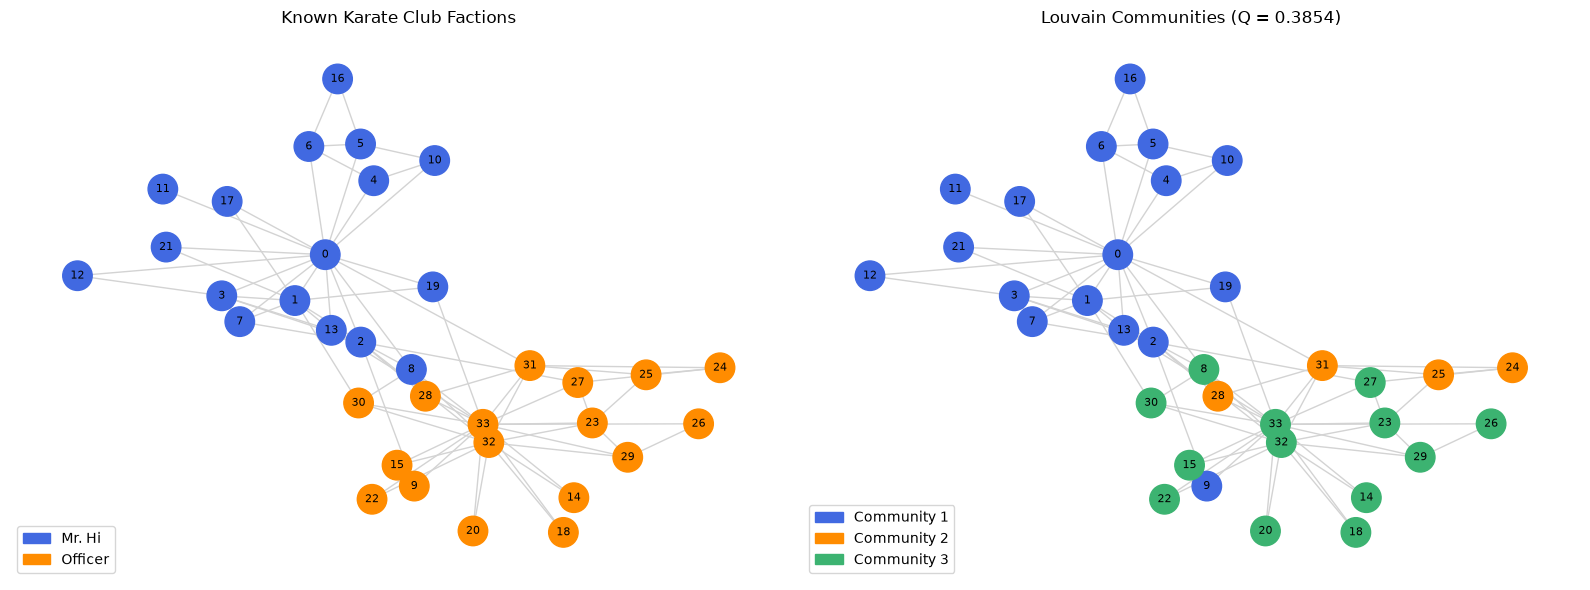

Figure saved: C:\Users\Lucky\Documents\University_Projects\cos802-network-analysis\figures\karate_louvain_vs_known.png


In [8]:

import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Fixed layout for both plots
pos = nx.spring_layout(G, seed=42)

# Known faction colours
faction_colors = {
    "Mr. Hi": "royalblue",
    "Officer": "darkorange"
}

known_colors = [
    faction_colors[G.nodes[node]["club"]]
    for node in G.nodes()
]

# Louvain community colours
community_palette = [
    "royalblue",
    "darkorange",
    "mediumseagreen"
]

louvain_colors = [
    community_palette[predicted[node]]
    for node in G.nodes()
]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Known factions
nx.draw_networkx(
    G,
    pos=pos,
    ax=axes[0],
    node_color=known_colors,
    node_size=450,
    font_size=8,
    edge_color="lightgray"
)

axes[0].set_title("Known Karate Club Factions")
axes[0].axis("off")

# Plot 2: Louvain communities
nx.draw_networkx(
    G,
    pos=pos,
    ax=axes[1],
    node_color=louvain_colors,
    node_size=450,
    font_size=8,
    edge_color="lightgray"
)

axes[1].set_title(
    f"Louvain Communities (Q = {modularity:.4f})"
)
axes[1].axis("off")

axes[0].legend(
    handles=[
        Patch(color=color, label=label)
        for label, color in faction_colors.items()
    ],
    loc="lower left"
)

axes[1].legend(
    handles=[
        Patch(
            color=community_palette[i],
            label=f"Community {i+1}"
        )
        for i in range(len(louvain_communities))
    ],
    loc="lower left"
)

plt.tight_layout()

# Save figure to project
from pathlib import Path
project_folder = (
    Path.home()
    / "Documents"
    / "University_Projects"
    / "cos802-network-analysis"
)


figure_path = (
    project_folder
    / "figures"
    / "karate_louvain_vs_known.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved:", figure_path)


In [9]:

comparison_df = pd.DataFrame({
    "Node": nodes,
    "Known_Faction": true_labels,
    "Louvain_Community": [
        predicted[node] + 1 for node in nodes
    ]
})

faction_comparison = pd.crosstab(
    comparison_df["Known_Faction"],
    comparison_df["Louvain_Community"]
)

display(faction_comparison)


Louvain_Community,1,2,3
Known_Faction,,,
Mr. Hi,16,0,1
Officer,1,4,12


### Louvain Community Detection: Initial Findings

Louvain identified three communities in the Zachary Karate Club network, compared with the two known factions. The detected partition achieved a modularity score of 0.3854, NMI of 0.5757 and ARI of 0.6124.

The contingency table shows that Community 1 contains 16 of the 17 members belonging to the Mr. Hi faction, while the Officer faction is divided mainly between Communities 2 and 3. Two nodes show disagreement between the detected communities and the dominant faction membership of their assigned groups: node 8 belongs to Mr. Hi but was assigned to Community 3, while node 9 belongs to the Officer faction but was assigned to Community 1.

These findings indicate that Louvain recovered much of the known faction structure while identifying an additional subgroup within the Officer faction. This difference reflects the fact that Louvain optimises modularity rather than agreement with known faction labels.

However, these results are based on a single run. Further experiments using different random seeds are needed to determine whether the three-community structure is stable.

## Louvain Stability Analysis

We repeat Louvain community detection across 30 random seeds to investigate variation in community assignments, modularity and agreement with known factions.

In [10]:

import numpy as np
import time

stability_results = []
partitions = []

for seed in range(30):

    start = time.perf_counter()

    communities = nx.community.louvain_communities(
        G,
        weight=None,
        resolution=1,
        seed=seed
    )

    elapsed = time.perf_counter() - start

    # Assign community IDs to nodes
    labels_dict = {
        node: i
        for i, community in enumerate(communities)
        for node in community
    }

    labels = [labels_dict[node] for node in nodes]
    partitions.append(labels)

    stability_results.append({
        "seed": seed,
        "n_communities": len(communities),
        "modularity": nx.community.modularity(
            G, communities, weight=None
        ),
        "nmi": normalized_mutual_info_score(
            true_labels, labels
        ),
        "ari": adjusted_rand_score(
            true_labels, labels
        ),
        "runtime_seconds": elapsed
    })

df_stability = pd.DataFrame(stability_results)

display(df_stability.head(10))


,seed,n_communities,modularity,nmi,ari,runtime_seconds
0,0,4,0.419790,0.587850,0.464591,0.003215
1,1,4,0.418803,0.489967,0.392239,0.002326
2,2,4,0.418803,0.489967,0.392239,0.001621
3,3,4,0.415105,0.600011,0.508864,0.001562
4,4,4,0.415105,0.600011,0.508864,0.001734
5,5,4,0.415598,0.497679,0.429291,0.001683
6,6,4,0.418803,0.489967,0.392239,0.001666
7,7,4,0.418803,0.489967,0.392239,0.001710
8,8,4,0.419790,0.587850,0.464591,0.001729
9,9,4,0.418803,0.489967,0.392239,0.001540


In [11]:

summary = df_stability[
    ["n_communities", "modularity", "nmi",
     "ari", "runtime_seconds"]
].agg(["mean", "std", "min", "max"])

display(summary.round(4))

print("\nNumber of communities across runs:")
print(
    df_stability["n_communities"]
    .value_counts()
    .sort_index()
)


,n_communities,modularity,nmi,ari,runtime_seconds
mean,4.0,0.4155,0.5342,0.4414,0.0020
std,0.0,0.0058,0.0515,0.0489,0.0007
min,4.0,0.3952,0.4869,0.3698,0.0013
max,4.0,0.4198,0.6000,0.5089,0.0034



Number of communities across runs:
n_communities
4    30
Name: count, dtype: int64


In [12]:

from itertools import combinations

pairwise_ari = [
    adjusted_rand_score(partitions[i], partitions[j])
    for i, j in combinations(range(len(partitions)), 2)
]

print("Pairwise stability results")
print("--------------------------")
print("Mean pairwise ARI:", round(np.mean(pairwise_ari), 4))
print("Std pairwise ARI:", round(np.std(pairwise_ari), 4))
print("Minimum pairwise ARI:", round(np.min(pairwise_ari), 4))
print("Maximum pairwise ARI:", round(np.max(pairwise_ari), 4))


Pairwise stability results
--------------------------
Mean pairwise ARI: 0.8612
Std pairwise ARI: 0.096
Minimum pairwise ARI: 0.6355
Maximum pairwise ARI: 1.0


### Louvain Stability Analysis: Findings

Louvain was evaluated across 30 runs using different random seeds (0–29) to assess the stability of its community detection results.

All 30 runs identified four communities, indicating consistency in the number of detected groups. The mean modularity was 0.4155 (SD = 0.0058), with values ranging from 0.3952 to 0.4198.

The mean pairwise Adjusted Rand Index (ARI) between runs was 0.8612, indicating strong overall agreement in community assignments. However, the minimum pairwise ARI of 0.6355 shows that some variation occurred between runs.

Agreement with the known Karate Club factions was lower, with mean NMI and ARI values of 0.5342 and 0.4414, respectively.

Interestingly, the original seed-42 run produced three communities with lower modularity (0.3854) but higher agreement with the known factions (ARI = 0.6124). This demonstrates that maximising modularity does not necessarily produce communities that best match known group membership.

Overall, Louvain showed relatively stable community detection under the tested settings, although some node assignments varied across runs. These findings provide a baseline for comparison with spectral clustering and label propagation.

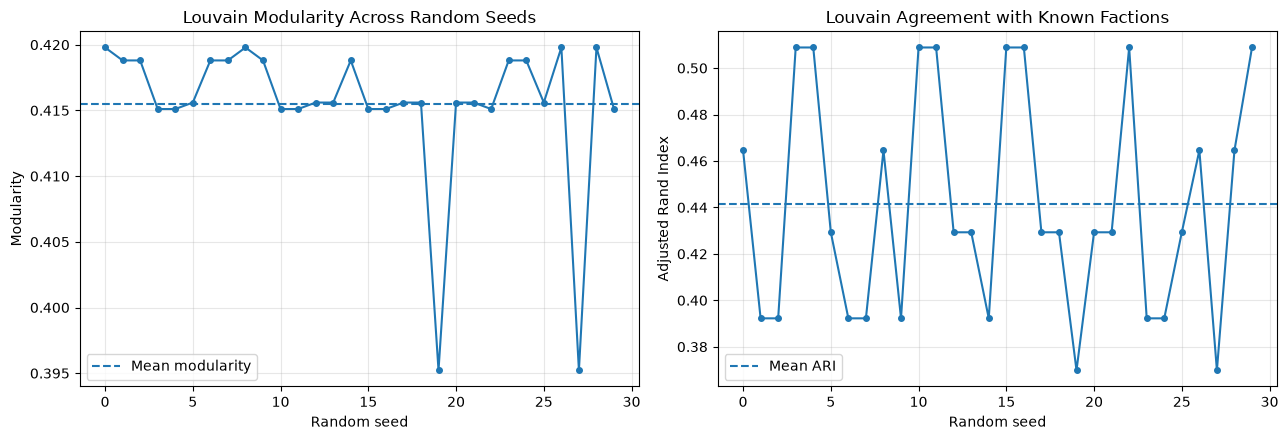

Saved: C:\Users\Lucky\Documents\University_Projects\cos802-network-analysis\figures\karate_louvain_stability.png


In [13]:

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Modularity across seeds
axes[0].plot(
    df_stability["seed"],
    df_stability["modularity"],
    marker="o",
    markersize=4
)

axes[0].axhline(
    df_stability["modularity"].mean(),
    linestyle="--",
    label="Mean modularity"
)

axes[0].set_title("Louvain Modularity Across Random Seeds")
axes[0].set_xlabel("Random seed")
axes[0].set_ylabel("Modularity")
axes[0].legend()
axes[0].grid(alpha=0.3)

# ARI with known factions
axes[1].plot(
    df_stability["seed"],
    df_stability["ari"],
    marker="o",
    markersize=4
)

axes[1].axhline(
    df_stability["ari"].mean(),
    linestyle="--",
    label="Mean ARI"
)

axes[1].set_title("Louvain Agreement with Known Factions")
axes[1].set_xlabel("Random seed")
axes[1].set_ylabel("Adjusted Rand Index")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

output_path = (
    project_folder
    / "figures"
    / "karate_louvain_stability.png"
)

plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", output_path)


In [14]:

results_path = project_folder / "results"

results_path.mkdir(parents=True, exist_ok=True)

df_stability.to_csv(
    results_path / "karate_louvain_stability.csv",
    index=False
)

print("Louvain stability results saved.")


Louvain stability results saved.


In [15]:

import subprocess

# Save notebook in Jupyter first (Ctrl + S)

files_to_commit = [
    "notebooks/02_community_detection.ipynb",
    "figures/karate_louvain_vs_known.png",
    "figures/karate_louvain_stability.png",
    "results/karate_louvain_stability.csv"
]

# Stage the experiment files
subprocess.run(
    ["git", "add", *files_to_commit],
    cwd=project_folder,
    check=True
)

# Commit the milestone
subprocess.run(
    [
        "git", "commit", "-m",
        "feat: implement and evaluate Louvain community detection"
    ],
    cwd=project_folder,
    check=True
)

# Push to GitHub
subprocess.run(
    ["git", "push", "origin", "main"],
    cwd=project_folder,
    check=True
)

print("Louvain experiment committed and pushed!")


Louvain experiment committed and pushed!


## Spectral Clustering

### Adjacency Matrix and Graph Laplacian

In [16]:

import numpy as np
import pandas as pd
from scipy.linalg import eigh

# Use the same node ordering as the Louvain experiment
nodes = list(G.nodes())

# Unweighted adjacency matrix
A = nx.to_numpy_array(
    G,
    nodelist=nodes,
    weight=None
)

# Degree matrix
D = np.diag(A.sum(axis=1))

# Unnormalised Laplacian
L = D - A

print("Adjacency matrix shape:", A.shape)
print("Degree matrix shape:", D.shape)
print("Laplacian matrix shape:", L.shape)

print("\nFirst 5 rows and columns of A:")
display(pd.DataFrame(A[:5, :5]))

print("\nFirst 5 rows and columns of L:")
display(pd.DataFrame(L[:5, :5]))

# Calculate eigenvalues of the unnormalised Laplacian
eigenvalues = eigh(L, eigvals_only=True)

print("\nFirst 10 eigenvalues:")
print(np.round(eigenvalues[:10], 4))


Adjacency matrix shape: (34, 34)
Degree matrix shape: (34, 34)
Laplacian matrix shape: (34, 34)

First 5 rows and columns of A:


,0,1,2,3,4
0,0.0,1.0,1.0,1.0,1.0
1,1.0,0.0,1.0,1.0,0.0
2,1.0,1.0,0.0,1.0,0.0
3,1.0,1.0,1.0,0.0,0.0
4,1.0,0.0,0.0,0.0,0.0



First 5 rows and columns of L:


,0,1,2,3,4
0,16.0,-1.0,-1.0,-1.0,-1.0
1,-1.0,9.0,-1.0,-1.0,0.0
2,-1.0,-1.0,10.0,-1.0,0.0
3,-1.0,-1.0,-1.0,6.0,0.0
4,-1.0,0.0,0.0,0.0,3.0



First 10 eigenvalues:
[0.     0.4685 0.9092 1.125  1.2594 1.5993 1.7619 1.8261 1.9551 2.    ]



### Spectral Clustering: Initial Experiment (k=2)

We apply spectral clustering to the unweighted Karate Club network using two clusters.

The known faction labels are not used during clustering. They are used only to evaluate the detected communities.

This experiment investigates whether spectral clustering can recover the two historical factions.


In [17]:

from sklearn.cluster import SpectralClustering
from sklearn.metrics import (
    normalized_mutual_info_score,
    adjusted_rand_score
)
import time

# Initialise spectral clustering
spectral_model = SpectralClustering(
    n_clusters=2,
    affinity="precomputed",
    assign_labels="kmeans",
    random_state=42,
    n_init=10
)

# Run the algorithm
start_time = time.perf_counter()

spectral_labels = spectral_model.fit_predict(A)

spectral_runtime = time.perf_counter() - start_time

# Convert labels into community sets
spectral_communities = [
    {
        nodes[i]
        for i in range(len(nodes))
        if spectral_labels[i] == cluster_id
    }
    for cluster_id in range(2)
]

print("Number of communities:", len(spectral_communities))
print("Runtime (seconds):", round(spectral_runtime, 6))

for i, community in enumerate(spectral_communities, start=1):
    print(f"Community {i}: {sorted(community)}")


Number of communities: 2
Runtime (seconds): 0.148359
Community 1: [0, 1, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21]
Community 2: [2, 8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]


In [18]:

# Calculate modularity
spectral_modularity = nx.community.modularity(
    G,
    spectral_communities,
    weight=None
)

# Compare with known factions
spectral_nmi = normalized_mutual_info_score(
    true_labels,
    spectral_labels
)

spectral_ari = adjusted_rand_score(
    true_labels,
    spectral_labels
)

print("Spectral Clustering Evaluation (k=2)")
print("------------------------------------")
print("Modularity:", round(spectral_modularity, 4))
print("NMI:", round(spectral_nmi, 4))
print("ARI:", round(spectral_ari, 4))
print("Runtime (seconds):", round(spectral_runtime, 6))


Spectral Clustering Evaluation (k=2)
------------------------------------
Modularity: 0.36
NMI: 0.7324
ARI: 0.7717
Runtime (seconds): 0.148359


### Spectral Clustering: Community Interpretation

In [19]:

# Compare detected communities with known factions

spectral_comparison = pd.DataFrame({
    "Node": nodes,
    "Known_Faction": true_labels,
    "Spectral_Community": spectral_labels + 1
})

spectral_table = pd.crosstab(
    spectral_comparison["Known_Faction"],
    spectral_comparison["Spectral_Community"]
)

display(spectral_table)

# Identify which known faction dominates each community
for community_id in sorted(
    spectral_comparison["Spectral_Community"].unique()
):
    members = spectral_comparison[
        spectral_comparison["Spectral_Community"] == community_id
    ]

    print(f"\nCommunity {community_id}:")
    print("Size:", len(members))
    print("Faction composition:")
    print(members["Known_Faction"].value_counts())


Spectral_Community,1,2
Known_Faction,,
Mr. Hi,15,2
Officer,0,17



Community 1:
Size: 15
Faction composition:
Known_Faction
Mr. Hi    15
Name: count, dtype: int64

Community 2:
Size: 19
Faction composition:
Known_Faction
Officer    17
Mr. Hi      2
Name: count, dtype: int64


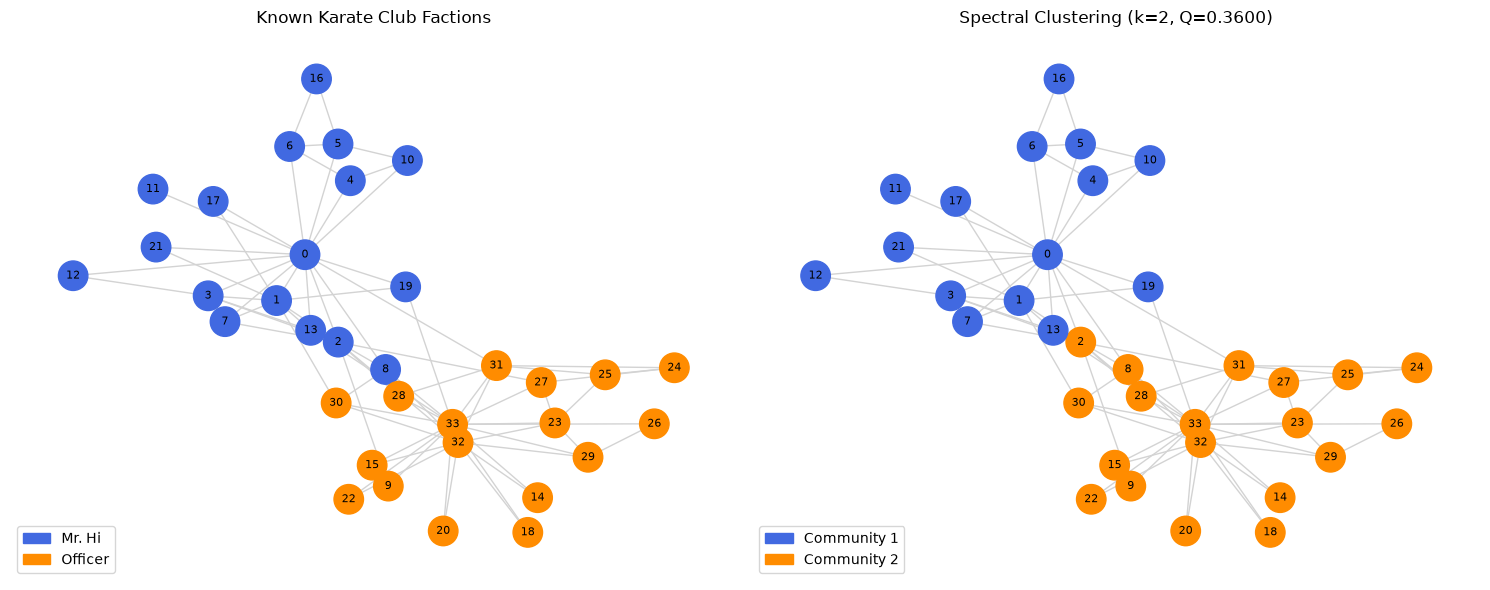

Saved: C:\Users\Lucky\Documents\University_Projects\cos802-network-analysis\figures\karate_spectral_vs_known.png


In [20]:

from matplotlib.patches import Patch

pos = nx.spring_layout(G, seed=42)

faction_colors = {
    "Mr. Hi": "royalblue",
    "Officer": "darkorange"
}

known_colors = [
    faction_colors[G.nodes[node]["club"]]
    for node in nodes
]

spectral_palette = ["royalblue", "darkorange"]

spectral_colors = [
    spectral_palette[label]
    for label in spectral_labels
]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

nx.draw_networkx(
    G,
    pos=pos,
    ax=axes[0],
    node_color=known_colors,
    node_size=450,
    font_size=8,
    edge_color="lightgray"
)

axes[0].set_title("Known Karate Club Factions")
axes[0].axis("off")

nx.draw_networkx(
    G,
    pos=pos,
    ax=axes[1],
    node_color=spectral_colors,
    node_size=450,
    font_size=8,
    edge_color="lightgray"
)

axes[1].set_title(
    f"Spectral Clustering (k=2, Q={spectral_modularity:.4f})"
)
axes[1].axis("off")

axes[0].legend(
    handles=[
        Patch(color=color, label=label)
        for label, color in faction_colors.items()
    ],
    loc="lower left"
)

axes[1].legend(
    handles=[
        Patch(color=spectral_palette[i],
              label=f"Community {i+1}")
        for i in range(2)
    ],
    loc="lower left"
)

plt.tight_layout()

output_path = (
    project_folder
    / "figures"
    / "karate_spectral_vs_known.png"
)

plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", output_path)


### Spectral Clustering (k=2): Initial Findings

Spectral clustering was applied to the unweighted Zachary Karate Club network using two clusters. The algorithm achieved a modularity score of 0.3600, NMI of 0.7324 and ARI of 0.7717.

The detected communities showed strong agreement with the known factions. All 17 Officer members were assigned to the same community, while 15 of the 17 Mr. Hi members were grouped together. Nodes 2 and 8, which belong to the Mr. Hi faction, were assigned to the community containing the Officer members.

Compared with the initial Louvain run, spectral clustering achieved higher agreement with the known factions but lower modularity. However, the number of clusters was fixed at two, matching the known number of factions. Therefore, this result should be treated as a validation experiment rather than evidence that spectral clustering is generally superior.

The next experiment investigates how spectral clustering results change when different numbers of clusters are specified.

### Spectral Clustering: Sensitivity to Cluster Count

We evaluate spectral clustering using k = 2 to 6 to investigate how the number of requested clusters affects modularity and agreement with known factions.

The known faction labels are used only for evaluation, not for fitting the clustering models.

In [21]:

spectral_k_results = []

for k in range(2, 7):

    model = SpectralClustering(
        n_clusters=k,
        affinity="precomputed",
        assign_labels="kmeans",
        random_state=42,
        n_init=10
    )

    start = time.perf_counter()
    labels = model.fit_predict(A)
    elapsed = time.perf_counter() - start

    communities = [
        {nodes[i] for i in range(len(nodes))
         if labels[i] == cluster_id}
        for cluster_id in np.unique(labels)
    ]

    spectral_k_results.append({
        "k": k,
        "n_communities": len(communities),
        "modularity": nx.community.modularity(
            G, communities, weight=None
        ),
        "nmi": normalized_mutual_info_score(
            true_labels, labels
        ),
        "ari": adjusted_rand_score(
            true_labels, labels
        ),
        "runtime_seconds": elapsed
    })

df_spectral_k = pd.DataFrame(spectral_k_results)

display(df_spectral_k.round(4))


,k,n_communities,modularity,nmi,ari,runtime_seconds
0,2,2,0.3600,0.7324,0.7717,0.0197
1,3,3,0.3991,0.6912,0.6841,0.0217
2,4,4,0.4102,0.4926,0.4071,0.0349
3,5,5,0.3988,0.5521,0.4166,0.0228
4,6,6,0.3653,0.3969,0.2177,0.0184


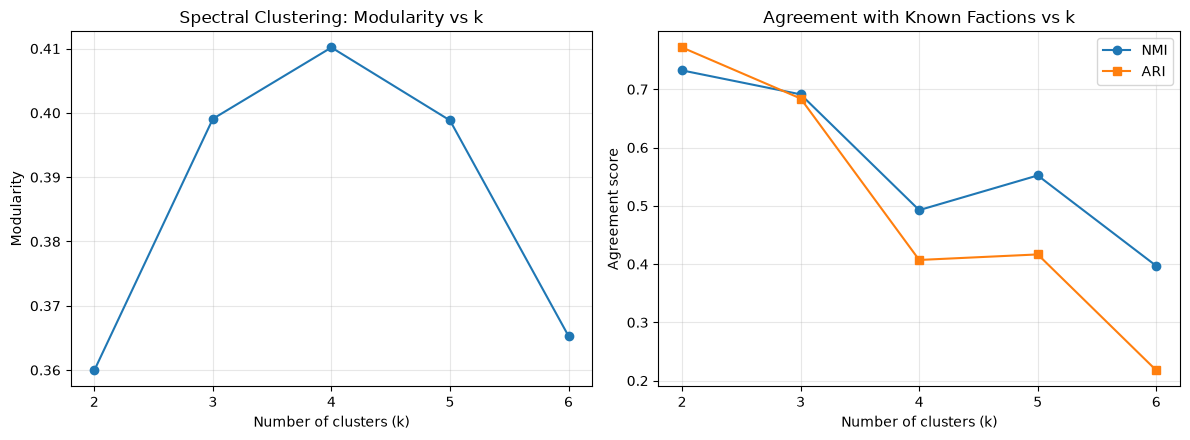

Saved: C:\Users\Lucky\Documents\University_Projects\cos802-network-analysis\figures\karate_spectral_k_sensitivity.png


In [22]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(
    df_spectral_k["k"],
    df_spectral_k["modularity"],
    marker="o"
)
axes[0].set_title("Spectral Clustering: Modularity vs k")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Modularity")
axes[0].set_xticks(range(2, 7))
axes[0].grid(alpha=0.3)

axes[1].plot(
    df_spectral_k["k"],
    df_spectral_k["nmi"],
    marker="o",
    label="NMI"
)
axes[1].plot(
    df_spectral_k["k"],
    df_spectral_k["ari"],
    marker="s",
    label="ARI"
)
axes[1].set_title("Agreement with Known Factions vs k")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Agreement score")
axes[1].set_xticks(range(2, 7))
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

output_path = (
    project_folder
    / "figures"
    / "karate_spectral_k_sensitivity.png"
)

plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", output_path)


### Spectral Clustering: Sensitivity Analysis Findings

Spectral clustering was evaluated using cluster counts ranging from two to six, with a fixed random seed of 42.

The highest modularity (0.4102) was achieved at four clusters, while the highest agreement with the known Karate Club factions occurred at two clusters (NMI = 0.7324; ARI = 0.7717).

Increasing the number of clusters from two to four improved modularity but reduced agreement with the known factions. Beyond four clusters, modularity decreased, reaching 0.3653 at six clusters.

These results demonstrate that spectral clustering is sensitive to the specified number of clusters. They also highlight the difference between identifying communities with strong structural separation and recovering known group membership.

The results are preliminary because each cluster count was evaluated using a single random seed. Further experiments across multiple random seeds are required to assess the stability of these findings.

### Spectral Clustering: Stability Across Random Seeds

We repeat spectral clustering across 30 random seeds for k=2 and k=4. We evaluate modularity, NMI, ARI, runtime and consistency of community assignments.

In [23]:

spectral_stability_results = []
spectral_partitions = {2: [], 4: []}

for k in [2, 4]:
    for seed in range(30):

        model = SpectralClustering(
            n_clusters=k,
            affinity="precomputed",
            assign_labels="kmeans",
            random_state=seed,
            n_init=10
        )

        start = time.perf_counter()
        labels = model.fit_predict(A)
        elapsed = time.perf_counter() - start

        communities = [
            {nodes[i] for i in range(len(nodes))
             if labels[i] == cluster_id}
            for cluster_id in np.unique(labels)
        ]

        spectral_partitions[k].append(labels.copy())

        spectral_stability_results.append({
            "k": k,
            "seed": seed,
            "n_communities": len(communities),
            "modularity": nx.community.modularity(
                G, communities, weight=None
            ),
            "nmi": normalized_mutual_info_score(
                true_labels, labels
            ),
            "ari": adjusted_rand_score(
                true_labels, labels
            ),
            "runtime_seconds": elapsed
        })

df_spectral_stability = pd.DataFrame(
    spectral_stability_results
)

display(df_spectral_stability.head(10))


,k,seed,n_communities,modularity,nmi,ari,runtime_seconds
0,2,0,2,0.359961,0.732378,0.771725,0.019295
1,2,1,2,0.359961,0.732378,0.771725,0.021408
2,2,2,2,0.359961,0.732378,0.771725,0.021809
3,2,3,2,0.359961,0.732378,0.771725,0.040057
4,2,4,2,0.359961,0.732378,0.771725,0.016163
5,2,5,2,0.359961,0.732378,0.771725,0.020807
6,2,6,2,0.359961,0.732378,0.771725,0.026905
7,2,7,2,0.359961,0.732378,0.771725,0.027467
8,2,8,2,0.359961,0.732378,0.771725,0.019274
9,2,9,2,0.359961,0.732378,0.771725,0.018554


In [24]:

metrics = [
    "modularity",
    "nmi",
    "ari",
    "runtime_seconds"
]

spectral_summary = (
    df_spectral_stability
    .groupby("k")[metrics]
    .agg(["mean", "std", "min", "max"])
)

display(spectral_summary.round(4))


modularity                          nmi                          ari       \
        mean  std     min     max    mean  std     min     max    mean  std   
k                                                                             
2     0.3600  0.0  0.3600  0.3600  0.7324  0.0  0.7324  0.7324  0.7717  0.0   
4     0.4102  0.0  0.4102  0.4102  0.4926  0.0  0.4926  0.4926  0.4071  0.0   

                  runtime_seconds                          
      min     max            mean     std     min     max  
k                                                          
2  0.7717  0.7717          0.0221  0.0067  0.0149  0.0465  
4  0.4071  0.4071          0.0271  0.0131  0.0170  0.0742

In [25]:

from itertools import combinations

spectral_pairwise_results = []

for k, partitions_k in spectral_partitions.items():

    scores = [
        adjusted_rand_score(a, b)
        for a, b in combinations(partitions_k, 2)
    ]

    spectral_pairwise_results.append({
        "k": k,
        "mean_pairwise_ari": np.mean(scores),
        "std_pairwise_ari": np.std(scores),
        "min_pairwise_ari": np.min(scores),
        "max_pairwise_ari": np.max(scores)
    })

df_spectral_pairwise = pd.DataFrame(
    spectral_pairwise_results
)

display(df_spectral_pairwise.round(4))


,k,mean_pairwise_ari,std_pairwise_ari,min_pairwise_ari,max_pairwise_ari
0,2,1.0,0.0,1.0,1.0
1,4,1.0,0.0,1.0,1.0


In [26]:

results_path = project_folder / "results"

df_spectral_k.to_csv(
    results_path / "karate_spectral_k_sensitivity.csv",
    index=False
)

df_spectral_stability.to_csv(
    results_path / "karate_spectral_stability.csv",
    index=False
)

df_spectral_pairwise.to_csv(
    results_path / "karate_spectral_pairwise_ari.csv",
    index=False
)

print("Spectral clustering results saved successfully.")


Spectral clustering results saved successfully.


### Spectral Clustering Stability: Findings

Spectral clustering was evaluated across 30 random seeds for two configurations: k=2 and k=4.

For both configurations, the algorithm produced identical community assignments across all 30 runs, achieving a mean pairwise Adjusted Rand Index (ARI) of 1.0000. The modularity, NMI and ARI scores also remained constant across runs.

For k=2, the mean modularity was 0.3600, NMI was 0.7324 and ARI against the known factions was 0.7717. For k=4, modularity increased to 0.4102, while NMI and ARI decreased to 0.4926 and 0.4071, respectively.

Compared with Louvain, which achieved a mean pairwise ARI of 0.8612, spectral clustering demonstrated greater consistency in community assignments under the tested conditions.

However, this stability was observed on a single small network with fixed algorithm parameters. The findings also show that stability across random seeds does not eliminate sensitivity to the number of clusters specified.

These results provide a basis for comparing the stability and community quality of the three algorithms in Research Question 1.

In [27]:

import subprocess

files_to_commit = [
    "notebooks/02_community_detection.ipynb",
    "figures/karate_spectral_vs_known.png",
    "figures/karate_spectral_k_sensitivity.png",
    "results/karate_spectral_k_sensitivity.csv",
    "results/karate_spectral_stability.csv",
    "results/karate_spectral_pairwise_ari.csv"
]

# Stage files
subprocess.run(
    ["git", "add", *files_to_commit],
    cwd=project_folder,
    check=True
)

# Commit
subprocess.run(
    [
        "git", "commit", "-m",
        "feat: evaluate spectral clustering and stability"
    ],
    cwd=project_folder,
    check=True
)

# Push to GitHub
subprocess.run(
    ["git", "push", "origin", "main"],
    cwd=project_folder,
    check=True
)

print("Spectral clustering experiment committed and pushed!")


Spectral clustering experiment committed and pushed!



## Label Propagation Community Detection

### Initial Experiment (seed=42)

We apply asynchronous Label Propagation to the unweighted Zachary Karate Club network.

The algorithm identifies communities by repeatedly updating node labels based on neighbouring nodes.

The known faction labels are not used during community detection. They are used only to evaluate the resulting communities.

We evaluate modularity, NMI, ARI, number of communities and runtime.


In [28]:

import time
import networkx as nx

# Run asynchronous Label Propagation
start_time = time.perf_counter()

lpa_communities = list(
    nx.community.asyn_lpa_communities(
        G,
        weight=None,
        seed=42
    )
)

lpa_runtime = time.perf_counter() - start_time

# Display detected communities
print("Number of communities:", len(lpa_communities))
print("Runtime (seconds):", round(lpa_runtime, 6))

for i, community in enumerate(lpa_communities, start=1):
    print(f"Community {i}: {sorted(community)}")


Number of communities: 4
Runtime (seconds): 0.001487
Community 1: [0, 1, 2, 3, 7, 11, 12, 13, 17, 19, 21, 28]
Community 2: [4, 5, 6, 10, 16]
Community 3: [8, 9, 14, 15, 18, 20, 22, 23, 26, 27, 29, 30, 32, 33]
Community 4: [24, 25, 31]


In [29]:

from sklearn.metrics import (
    normalized_mutual_info_score,
    adjusted_rand_score
)

# Convert community sets into node labels
lpa_predicted = {
    node: community_id
    for community_id, community in enumerate(lpa_communities)
    for node in community
}

lpa_labels = [
    lpa_predicted[node]
    for node in nodes
]

# Calculate modularity
lpa_modularity = nx.community.modularity(
    G,
    lpa_communities,
    weight=None
)

# Agreement with known factions
lpa_nmi = normalized_mutual_info_score(
    true_labels,
    lpa_labels
)

lpa_ari = adjusted_rand_score(
    true_labels,
    lpa_labels
)

print("Label Propagation Evaluation")
print("---------------------------")
print("Communities:", len(lpa_communities))
print("Modularity:", round(lpa_modularity, 4))
print("NMI:", round(lpa_nmi, 4))
print("ARI:", round(lpa_ari, 4))
print("Runtime (seconds):", round(lpa_runtime, 6))


Label Propagation Evaluation
---------------------------
Communities: 4
Modularity: 0.4033
NMI: 0.5056
ARI: 0.4588
Runtime (seconds): 0.001487


### Label Propagation: Community Visualisation

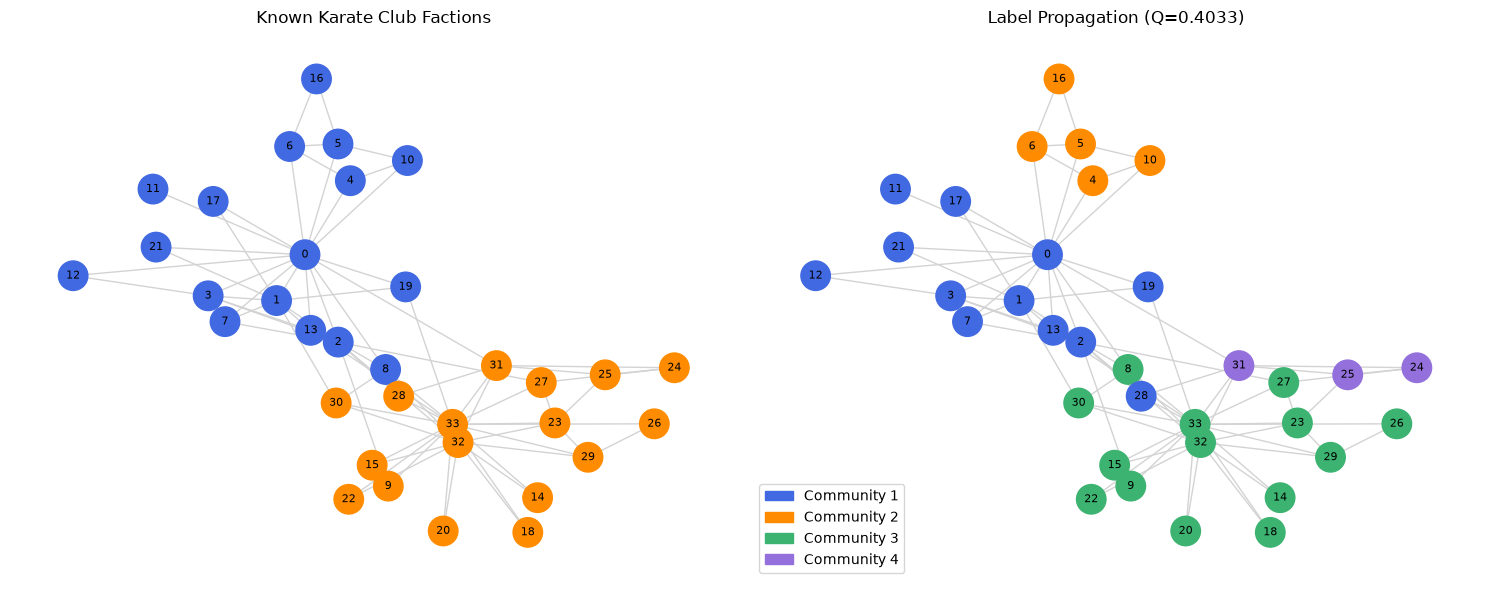

Saved: C:\Users\Lucky\Documents\University_Projects\cos802-network-analysis\figures\karate_lpa_vs_known.png


In [30]:

from matplotlib.patches import Patch

# Reuse the fixed layout from previous experiments
pos = nx.spring_layout(G, seed=42)

lpa_palette = [
    "royalblue",
    "darkorange",
    "mediumseagreen",
    "mediumpurple"
]

lpa_colors = [
    lpa_palette[lpa_predicted[node]]
    for node in nodes
]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Known factions
nx.draw_networkx(
    G,
    pos=pos,
    ax=axes[0],
    node_color=known_colors,
    node_size=450,
    font_size=8,
    edge_color="lightgray"
)

axes[0].set_title("Known Karate Club Factions")
axes[0].axis("off")

# Label Propagation
nx.draw_networkx(
    G,
    pos=pos,
    ax=axes[1],
    node_color=lpa_colors,
    node_size=450,
    font_size=8,
    edge_color="lightgray"
)

axes[1].set_title(
    f"Label Propagation (Q={lpa_modularity:.4f})"
)
axes[1].axis("off")

axes[1].legend(
    handles=[
        Patch(color=lpa_palette[i], label=f"Community {i+1}")
        for i in range(len(lpa_communities))
    ],
    loc="lower left"
)

plt.tight_layout()

output_path = (
    project_folder
    / "figures"
    / "karate_lpa_vs_known.png"
)

plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", output_path)


In [31]:

lpa_comparison = pd.DataFrame({
    "Node": nodes,
    "Known_Faction": true_labels,
    "LPA_Community": [
        lpa_predicted[node] + 1
        for node in nodes
    ]
})

lpa_table = pd.crosstab(
    lpa_comparison["Known_Faction"],
    lpa_comparison["LPA_Community"]
)

display(lpa_table)


LPA_Community,1,2,3,4
Known_Faction,,,,
Mr. Hi,11,5,1,0
Officer,1,0,13,3


### Label Propagation: Initial Findings

Asynchronous Label Propagation identified four communities in the Zachary Karate Club network, achieving a modularity score of 0.4033, NMI of 0.5056 and ARI of 0.4588.

The detected communities broadly followed the known faction structure but divided both historical factions into smaller groups. Communities 1 and 2 predominantly contained Mr. Hi members, while Communities 3 and 4 predominantly contained Officer members.

Two nodes were assigned to communities dominated by the opposite faction: node 8, belonging to Mr. Hi, and node 9, belonging to the Officer faction. These nodes were also exceptions in the initial Louvain experiment.

The results suggest that Label Propagation identifies meaningful local groupings rather than simply reproducing the two known factions. However, the experiment represents a single random seed, and further testing is needed to establish whether these communities are stable.

The next experiment evaluates Label Propagation across 30 random seeds to assess changes in community count, modularity, agreement with known factions and community membership.

### Label Propagation: Stability Analysis

We repeat asynchronous Label Propagation across 30 random seeds to evaluate variation in community count, modularity, agreement with known factions and community assignments.m

In [34]:

import numpy as np
import pandas as pd
import time

lpa_stability_results = []
lpa_partitions = []

for seed in range(30):

    start = time.perf_counter()

    communities = list(
        nx.community.asyn_lpa_communities(
            G,
            weight=None,
            seed=seed
        )
    )

    elapsed = time.perf_counter() - start

    # Convert communities into labels
    label_map = {
        node: i
        for i, community in enumerate(communities)
        for node in community
    }

    labels = [label_map[node] for node in nodes]
    lpa_partitions.append(labels)

    lpa_stability_results.append({
        "seed": seed,
        "n_communities": len(communities),
        "modularity": nx.community.modularity(
            G, communities, weight=None
        ),
        "nmi": normalized_mutual_info_score(
            true_labels, labels
        ),
        "ari": adjusted_rand_score(
            true_labels, labels
        ),
        "runtime_seconds": elapsed
    })

df_lpa_stability = pd.DataFrame(lpa_stability_results)

display(df_lpa_stability.head(10))


,seed,n_communities,modularity,nmi,ari,runtime_seconds
0,0,3,0.402038,0.568380,0.590553,0.000766
1,1,3,0.385355,0.575734,0.612440,0.001395
2,2,2,0.371795,0.677243,0.771626,0.000371
3,3,2,0.132807,0.206487,0.072402,0.001084
4,4,3,0.399080,0.691249,0.684142,0.001275
5,5,3,0.329799,0.542394,0.505645,0.000895
6,6,3,0.399080,0.691249,0.684142,0.000968
7,7,2,0.359961,0.732378,0.771725,0.000517
8,8,2,0.371466,0.837169,0.882258,0.000844
9,9,4,0.376151,0.449919,0.427496,0.000349


In [35]:

metrics = [
    "n_communities",
    "modularity",
    "nmi",
    "ari",
    "runtime_seconds"
]

lpa_summary = (
    df_lpa_stability[metrics]
    .agg(["mean", "std", "min", "max"])
)

display(lpa_summary.round(4))

print("\nNumber of communities across runs:")
print(
    df_lpa_stability["n_communities"]
    .value_counts()
    .sort_index()
)


,n_communities,modularity,nmi,ari,runtime_seconds
mean,3.2333,0.3524,0.5701,0.5587,0.0007
std,0.8584,0.0794,0.1561,0.2050,0.0003
min,2.0000,0.1328,0.2065,0.0724,0.0003
max,5.0000,0.4156,0.8372,0.8823,0.0015



Number of communities across runs:
n_communities
2     6
3    13
4     9
5     2
Name: count, dtype: int64


In [36]:

from itertools import combinations

lpa_pairwise_ari = [
    adjusted_rand_score(a, b)
    for a, b in combinations(lpa_partitions, 2)
]

print("Label Propagation Stability")
print("---------------------------")
print("Mean pairwise ARI:",
      round(np.mean(lpa_pairwise_ari), 4))
print("Std pairwise ARI:",
      round(np.std(lpa_pairwise_ari), 4))
print("Minimum pairwise ARI:",
      round(np.min(lpa_pairwise_ari), 4))
print("Maximum pairwise ARI:",
      round(np.max(lpa_pairwise_ari), 4))


Label Propagation Stability
---------------------------
Mean pairwise ARI: 0.598
Std pairwise ARI: 0.2305
Minimum pairwise ARI: -0.0203
Maximum pairwise ARI: 1.0


In [37]:

results_path = project_folder / "results"

df_lpa_stability.to_csv(
    results_path / "karate_lpa_stability.csv",
    index=False
)

print("Label Propagation stability results saved.")


Label Propagation stability results saved.


### Label Propagation Stability: Findings

Asynchronous Label Propagation was evaluated across 30 random seeds on the unweighted Zachary Karate Club network.

The number of detected communities varied between two and five, with an average of 3.23. Three communities were detected most frequently, occurring in 13 of the 30 runs.

The mean modularity was 0.3524 (SD = 0.0794), with values ranging from 0.1328 to 0.4156. Agreement with the known factions also varied substantially, with mean NMI of 0.5701 and mean ARI of 0.5587.

The mean pairwise ARI between runs was 0.5980, considerably lower than the corresponding values for Louvain (0.8612) and spectral clustering (1.0000). This indicates that Label Propagation was less consistent in its community assignments under the tested conditions.

Although Label Propagation achieved the lowest mean runtime (approximately 0.0007 seconds), its results were more sensitive to random seed selection.

Overall, the experiment demonstrates that Label Propagation can produce meaningful communities quickly, but its output may vary substantially between runs. This highlights the importance of evaluating both community quality and stability rather than relying on a single execution.